In [1]:
using VoronoiMeshes, NCDatasets, DelaunayTriangulation, CairoMakie
include("juliaDEC.jl")

plot_cochain

In [2]:
# Parameters
L = 1.0                 # domain length
dx_list = [3.0^(-i-2) for i in 1:7]         # advection speed
dt_list = 0.23*dx_list
T = 1.0
c = 1.0
error_list = []

for (i, dx) in enumerate(dx_list)
    println("testing dx = $dx")
    x = collect(0.0:dx:1.0)
    dt = 0.1*dt_list[i]
    steps = Int(floor(T / dt))
    # Initial condition: Gaussian pulse
    center = 0.5
    u = exp.(-100 .* (x .- center).^2)
    usol = exp.(-100 .* (x .- center).^2)
    CFL = c*dt/dx

    t = 0
    # Upwind loop
    for n in 1:steps
        u = u .- CFL .* (u .- circshift(u, 1))  # circshift handles periodic BC
        t+= dt
    end

    #fig = Figure()
    #ax = Axis(fig[1, 1], xlabel="x", ylabel="u", title="Gaussian Pulse")
    #lines!(ax, x, usol, label="Initial Condition")
    #lines!(ax, x, u, label="Upwind")
    #axislegend()
    #display(fig)
    println("t = $t")
    error = maximum(abs.(u - usol))
    push!(error_list, error)
    println(error)
end

#compute order of convergence
for i = 2:length(error_list)
    order = log(error_list[i]/error_list[i-1]) / log(dx_list[i]/dx_list[i-1])
    println("Order Linf between meshes $(i-1) and $i: $order")
end




testing dx = 0.037037037037037035
t = 0.9992222222222324
0.6382126823842984
testing dx = 0.012345679012345678
t = 0.9997901234567189
0.46285791516967656
testing dx = 0.00411522633744856
t = 0.9999794238681047
0.2570801035036203
testing dx = 0.0013717421124828531
t = 0.9999794238687927
0.11249615602062801
testing dx = 0.0004572473708276177
t = 0.9999899405569965
0.04205705045889774
testing dx = 0.00015241579027587258
t = 0.9999969516783439
0.01462146328910685
testing dx = 5.080526342529086e-5
t = 0.9999992887390213
0.00494493349617231
Order Linf between meshes 1 and 2: 0.2924156781878176
Order Linf between meshes 2 and 3: 0.5352501617322396
Order Linf between meshes 3 and 4: 0.7522842037041811
Order Linf between meshes 4 and 5: 0.8955771036569616
Order Linf between meshes 5 and 6: 0.9617009697036821
Order Linf between meshes 6 and 7: 0.986814941346313


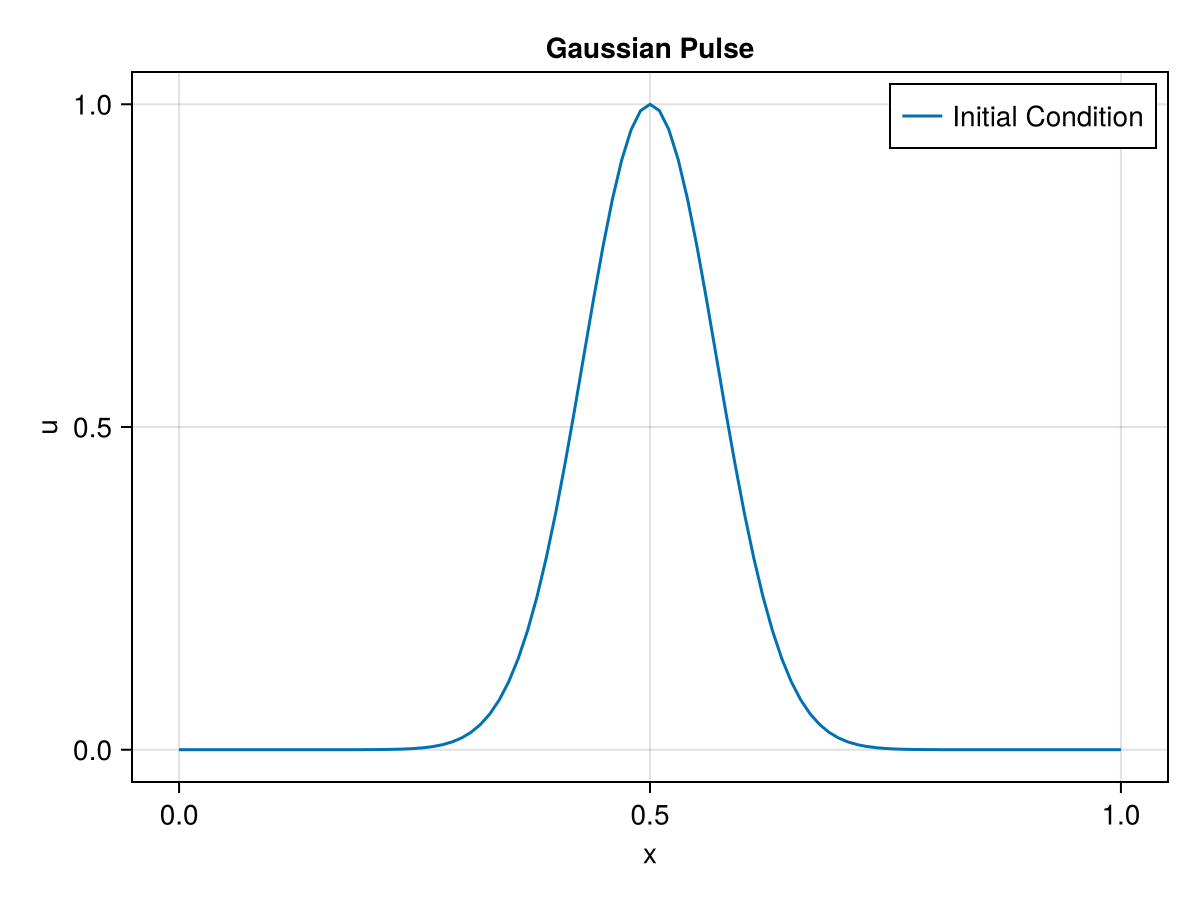

CairoMakie.Screen{IMAGE}


In [23]:
dx =0.01
x = collect(0.0:dx:1.0)
center = 0.5
usol = exp.(-100 .* (x .- center).^2)

fig = Figure()
ax = Axis(fig[1, 1], xlabel="x", ylabel="u", title="Gaussian Pulse")
lines!(ax, x, usol, label="Initial Condition")
axislegend()
display(fig)

In [5]:
using VoronoiMeshes
using LinearAlgebra
using SparseArrays
using JLD2
using DelaunayTriangulation, NCDatasets
include("juliaDEC.jl")

function save_lsq_matrices()
    # Arrays to store matrices
    matrices_regular = Dict{Int, Dict{String, SparseMatrixCSC{Float64, Int}}}()
    matrices_irregular = Dict{Int, Dict{String, SparseMatrixCSC{Float64, Int}}}()
    
    # Process meshes from 1 to 7 (as seen in mesh_generator.jl)
    for i in 1:7
        println("Processing mesh $i")
        
        # Regular mesh
        mesh_regular = VoronoiMesh("meshes/mesh$(i)_regular.nc")
        matrices_regular[i] = Dict{String, SparseMatrixCSC{Float64, Int}}()
        
        # Get LSQ matrices for regular mesh
        matrices_regular[i]["lsq_linear"] = hodge_star_lsq_matrix(mesh_regular, true, true)
        matrices_regular[i]["lsq_quadratic"] = hodge_star_lsq_matrix(mesh_regular, true, false)
        
        # Irregular mesh
        mesh_irregular = VoronoiMesh("meshes/mesh$(i).nc")
        matrices_irregular[i] = Dict{String, SparseMatrixCSC{Float64, Int}}()
        
        # Get LSQ matrices for irregular mesh
        matrices_irregular[i]["lsq_linear"] = hodge_star_lsq_matrix(mesh_irregular, true, true)
        matrices_irregular[i]["lsq_quadratic"] = hodge_star_lsq_matrix(mesh_irregular, true, false)
    end
    
    # Save matrices to file
    @save "lsq_matrices.jld2" matrices_regular matrices_irregular
    println("Matrices saved to lsq_matrices.jld2")
end

# Run the function
save_lsq_matrices() 

Processing mesh 1
Processing mesh 2
Processing mesh 3
Processing mesh 4
Processing mesh 5
Processing mesh 6
Processing mesh 7
Matrices saved to lsq_matrices.jld2


In [1]:
using JLD2
using LinearAlgebra
using SparseArrays
using VoronoiMeshes
using DelaunayTriangulation, NCDatasets

# Load the matrices
@load "lsq_matrices.jld2" matrices_regular matrices_irregular

# Example operations with the matrices
function demonstrate_matrix_operations()
    # Let's use mesh level 3 as an example
    level = 7
    
    # Get matrices for regular mesh
    A_linear_reg = matrices_regular[level]["lsq_linear"]
    A_quad_reg = matrices_regular[level]["lsq_quadratic"]
    
    # 4. Example with vector
    n = size(A_linear_reg, 2)
    test_vector = ones(n)
    
    println("\nMatrix-vector product example:")
    result_linear = A_linear_reg * test_vector
    result_quad = A_quad_reg * test_vector
    println("Norm of result (linear): ", norm(result_linear))
    println("Norm of result (quadratic): ", norm(result_quad))
end

# Run the demonstration
demonstrate_matrix_operations() 


Matrix-vector product example:
Norm of result (linear): 72.5285912069478
Norm of result (quadratic): 224.04094888288026


In [2]:
mesh = VoronoiMesh("meshes/mesh7.nc")
maximum(mesh.edges.lengthDual)

0.005528084322002609

65536